# HMM A/B Comparison — 2-feature vs 3-feature

## Mục đích
Cung cấp **bằng chứng số liệu** cho claim trong Section 3.5 của paper:
> *Bổ sung `port_ret_ma20` giúp HMM phân biệt Bear (down-trend thật) vs HighVol Recovery (vol cao + trend dương)*

## Test cases
- **Variant A**: 2 features `(port_ret, port_vol_20)`
- **Variant B**: 3 features `(port_ret, port_vol_20, port_ret_ma20)`

## Kỳ vọng
- Variant A: Bear state có return **dương** (mixed: crash + recovery)
- Variant B: Bear state có return **âm** (true Bear market)

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
import seaborn as sns
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

ROOT = os.path.abspath('../../')
FEAT_PATH = f'{ROOT}/data/processed/v2/features_all.csv'
OUT_PATH  = f'{ROOT}/data/processed/v2/regime_comparison.csv'

TRAIN_END = '2022-06-30'
RANDOM_SEED = 42

REGIME_COLORS = {
    'Bull'    : '#28a745',
    'Sideways': '#ffc107',
    'Bear'    : '#dc3545',
}
REGIME_BG = {
    'Bull'    : '#d4edda',
    'Sideways': '#fff3cd',
    'Bear'    : '#f8d7da',
}

SPECIAL_PERIODS = {
    'COVID crash':     ('2020-03-01', '2020-03-31'),
    'COVID recovery':  ('2020-05-01', '2020-06-30'),
    'Recovery 2021':   ('2021-01-01', '2021-06-30'),
    'Bond crisis':     ('2022-09-15', '2022-11-30'),
    'FTSE upgrade':    ('2025-09-01', '2025-12-31'),
}
print('Setup OK')

Setup OK


## 1. Load data + build portfolio series

In [2]:
df = pd.read_csv(FEAT_PATH, parse_dates=['Date'])
print(f'features_all.csv: {df.shape}')

port = (
    df.groupby('Date')[['ret_1d', 'vol_20d']]
    .mean()
    .rename(columns={'ret_1d': 'port_ret', 'vol_20d': 'port_vol20'})
)
port.index = pd.to_datetime(port.index)
port = port.sort_index()
port['port_ret_ma20'] = port['port_ret'].rolling(20).mean()

print(f'Portfolio series: {port.shape[0]} days')
print(f'Date range: {port.index.min().date()} → {port.index.max().date()}')
port.head()

features_all.csv: (48642, 42)
Portfolio series: 3245 days
Date range: 2013-01-02 → 2025-12-31


,port_ret,port_vol20,port_ret_ma20
Date,,,
2013-01-02,NaN,NaN,NaN
2013-01-03,-0.001826,NaN,NaN
2013-01-04,0.015066,NaN,NaN
2013-01-07,0.017801,NaN,NaN
2013-01-08,0.028389,NaN,NaN


## 2. Fit HMM cho cả 2 variants

In [3]:
def fit_hmm_variant(port, features, variant_name):
    """Fit HMM, label by Sharpe, return (states_series, summary_df)."""
    p = port.dropna(subset=features).copy()
    train_mask = p.index <= TRAIN_END
    X = p[features].values

    sc = StandardScaler()
    X_tr   = sc.fit_transform(X[train_mask])
    X_full = sc.transform(X)

    model = GaussianHMM(n_components=3, covariance_type='full',
                        n_iter=200, random_state=RANDOM_SEED, tol=1e-4)
    model.fit(X_tr)
    states = model.predict(X_full)

    rows = []
    for s in range(3):
        mask = states == s
        if mask.sum() == 0:
            continue
        ret = p['port_ret'].values[mask].mean()
        vol = p['port_ret'].values[mask].std()
        rows.append({
            'raw_state': s, 'n_days': int(mask.sum()),
            'pct': round(mask.mean()*100, 1),
            'ret_daily': round(ret, 6),
            'ret_annual_pct': round(ret*252*100, 2),
            'vol_annual_pct': round(vol*np.sqrt(252)*100, 2),
            'sharpe_daily': round(ret/(vol+1e-9), 3),
        })
    summary = pd.DataFrame(rows).sort_values('sharpe_daily', ascending=False).reset_index(drop=True)
    summary['regime_label'] = ['Bull', 'Sideways', 'Bear']
    summary['variant'] = variant_name

    label_map = dict(zip(summary['raw_state'], summary['regime_label']))
    states_labeled = pd.Series([label_map[s] for s in states], index=p.index, name=variant_name)

    return states_labeled, summary, model

states_a, summary_a, model_a = fit_hmm_variant(port, ['port_ret', 'port_vol20'], 'A')
states_b, summary_b, model_b = fit_hmm_variant(port, ['port_ret', 'port_vol20', 'port_ret_ma20'], 'B')

print('=== VARIANT A: 2 features ===')
print(summary_a[['regime_label','n_days','pct','ret_annual_pct','vol_annual_pct','sharpe_daily']].to_string(index=False))
print('\n=== VARIANT B: 3 features ===')
print(summary_b[['regime_label','n_days','pct','ret_annual_pct','vol_annual_pct','sharpe_daily']].to_string(index=False))

=== VARIANT A: 2 features ===
regime_label  n_days  pct  ret_annual_pct  vol_annual_pct  sharpe_daily
        Bull     977 30.3           29.29           12.22         0.151
    Sideways     956 29.6           15.89           12.84         0.078
        Bear    1292 40.1            2.87           27.56         0.007

=== VARIANT B: 3 features ===
regime_label  n_days  pct  ret_annual_pct  vol_annual_pct  sharpe_daily
        Bull    1573 48.8           21.97           11.78         0.117
    Sideways    1016 31.5           22.50           18.85         0.075
        Bear     636 19.7          -15.56           33.27        -0.029


## 3. Visualization 1 — Side-by-side stats comparison

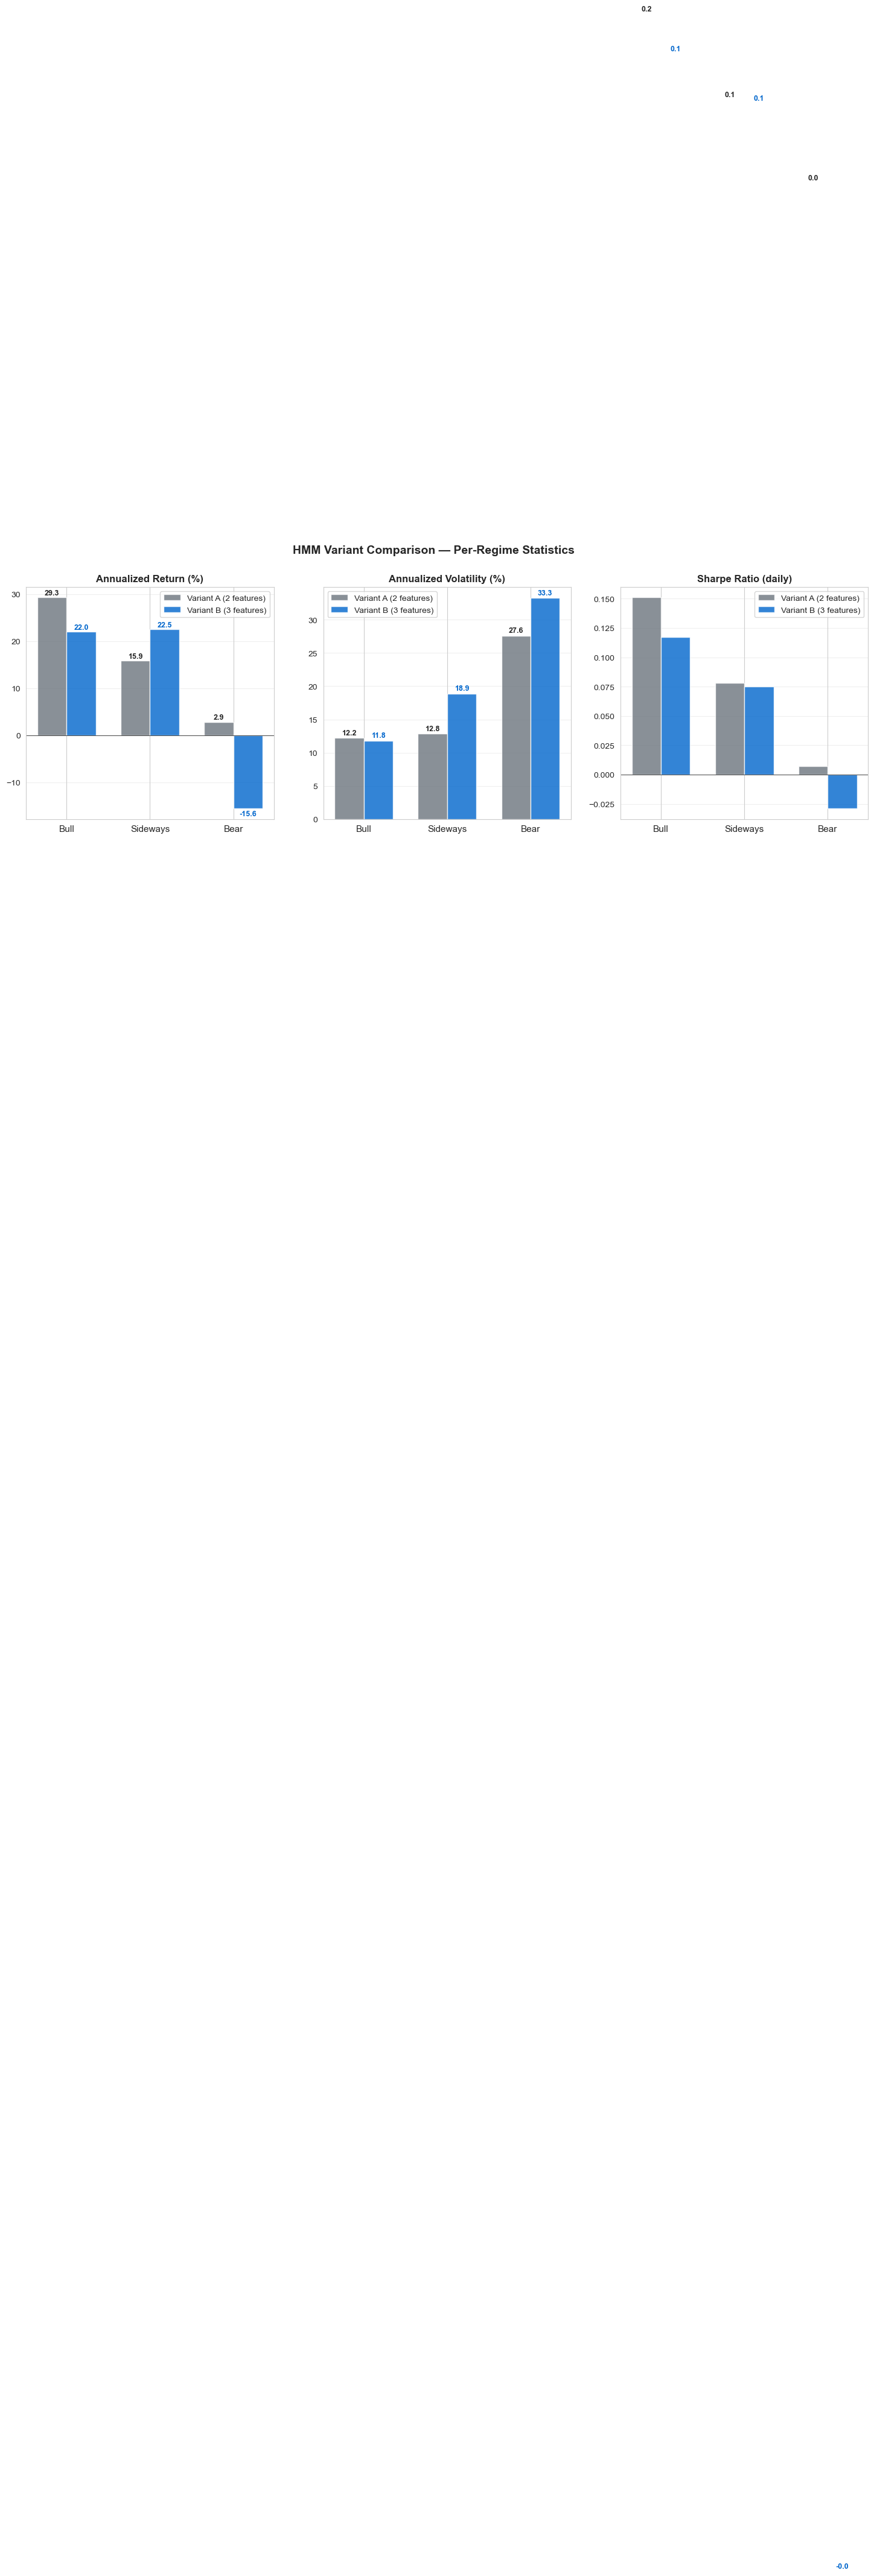


>> KEY EVIDENCE:
   Bear annualized return: A = +2.87%  vs  B = -15.56%
   Difference: +18.43 percentage points


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ('ret_annual_pct', 'Annualized Return (%)', 'YlGnBu'),
    ('vol_annual_pct', 'Annualized Volatility (%)', 'YlOrRd'),
    ('sharpe_daily', 'Sharpe Ratio (daily)', 'RdYlGn'),
]

x = np.arange(3)
width = 0.35
regimes = ['Bull', 'Sideways', 'Bear']

for ax, (col, title, _) in zip(axes, metrics):
    vals_a = [summary_a[summary_a['regime_label']==r][col].iloc[0] for r in regimes]
    vals_b = [summary_b[summary_b['regime_label']==r][col].iloc[0] for r in regimes]
    
    bars_a = ax.bar(x - width/2, vals_a, width, label='Variant A (2 features)', color='#6c757d', alpha=0.8)
    bars_b = ax.bar(x + width/2, vals_b, width, label='Variant B (3 features)', color='#0066cc', alpha=0.8)
    
    # Annotate values on bars
    for bar, v in zip(bars_a, vals_a):
        ax.text(bar.get_x()+bar.get_width()/2, v + (0.5 if v>=0 else -1.5), f'{v:.1f}',
                ha='center', fontsize=9, fontweight='bold')
    for bar, v in zip(bars_b, vals_b):
        ax.text(bar.get_x()+bar.get_width()/2, v + (0.5 if v>=0 else -1.5), f'{v:.1f}',
                ha='center', fontsize=9, fontweight='bold', color='#0066cc')
    
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(regimes, fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=10, loc='best')
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('HMM Variant Comparison — Per-Regime Statistics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{ROOT}/notebooks/eda/regime_compare_stats.png', dpi=150, bbox_inches='tight')
plt.show()

# Key callout
bear_a = summary_a[summary_a['regime_label']=='Bear'].iloc[0]
bear_b = summary_b[summary_b['regime_label']=='Bear'].iloc[0]
print(f'\n>> KEY EVIDENCE:')
print(f'   Bear annualized return: A = {bear_a["ret_annual_pct"]:+.2f}%  vs  B = {bear_b["ret_annual_pct"]:+.2f}%')
print(f'   Difference: {bear_a["ret_annual_pct"] - bear_b["ret_annual_pct"]:+.2f} percentage points')

## 4. Visualization 2 — Regime distribution stacked bars

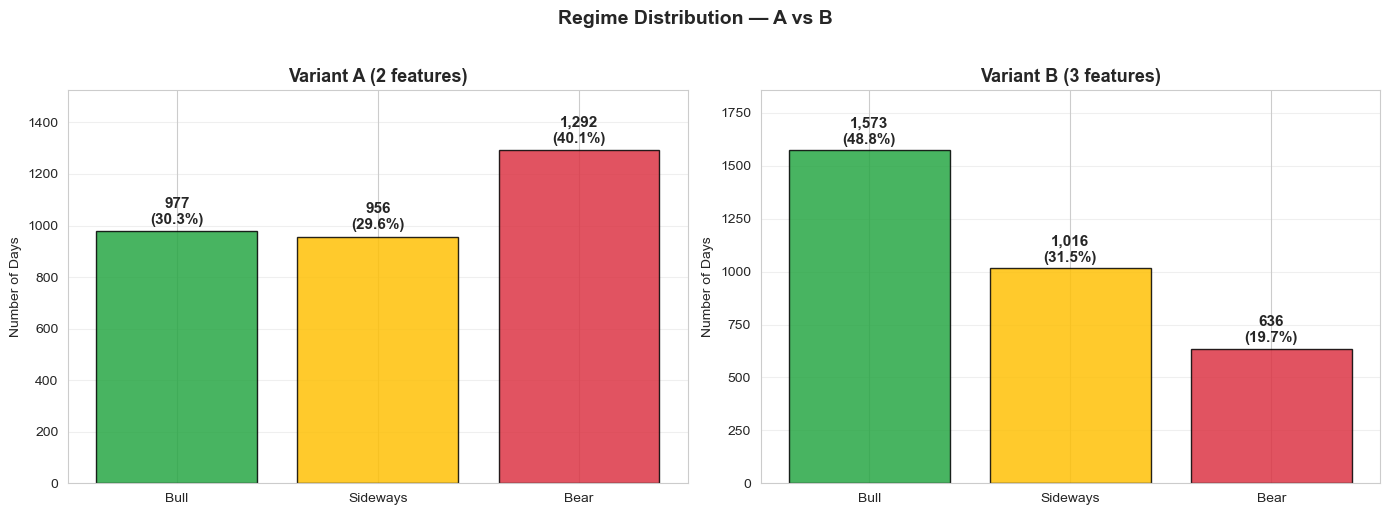

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (states, summary, name) in zip(
    axes,
    [(states_a, summary_a, 'Variant A (2 features)'),
     (states_b, summary_b, 'Variant B (3 features)')]
):
    counts = states.value_counts().reindex(['Bull','Sideways','Bear'])
    pcts = counts / counts.sum() * 100
    
    colors = [REGIME_COLORS[r] for r in counts.index]
    bars = ax.bar(counts.index, counts.values, color=colors, alpha=0.85, edgecolor='black')
    
    for bar, pct, n in zip(bars, pcts, counts):
        ax.text(bar.get_x()+bar.get_width()/2, n + 30,
                f'{n:,}\n({pct:.1f}%)', ha='center', fontsize=11, fontweight='bold')
    
    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_ylabel('Number of Days')
    ax.set_ylim(0, max(counts) * 1.18)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Regime Distribution — A vs B', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{ROOT}/notebooks/eda/regime_compare_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Visualization 3 — Confusion matrix giữa A và B

Khi nào A và B disagree?

Total agreement: 49.4% of days
Total days analyzed: 3225


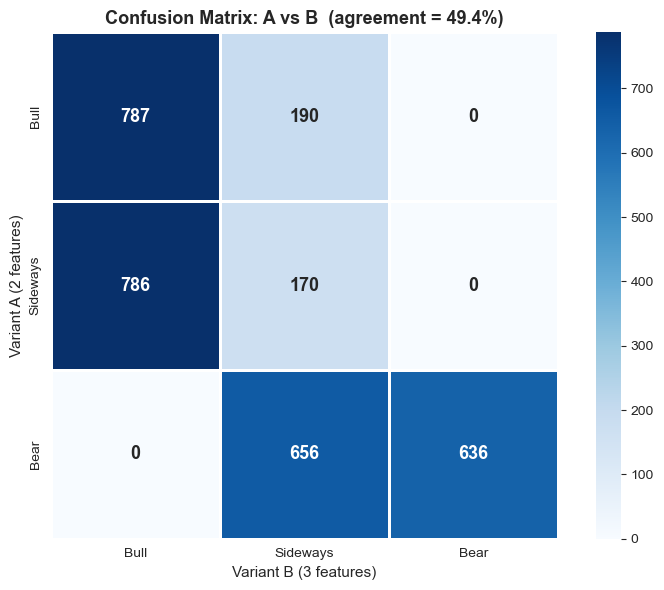


=== Disagreement breakdown ===
(rows = Variant A label, cols = Variant B label)
Diagonal = agree, off-diagonal = disagree

Total disagreement: 1632 days (50.6%)


In [6]:
# Align trên ngày chung
common_idx = states_a.index.intersection(states_b.index)
a = states_a.loc[common_idx]
b = states_b.loc[common_idx]

confusion = pd.crosstab(a, b, rownames=['Variant A'], colnames=['Variant B'])
confusion = confusion.reindex(index=['Bull','Sideways','Bear'], columns=['Bull','Sideways','Bear'], fill_value=0)

agree = (a == b).mean() * 100
print(f'Total agreement: {agree:.1f}% of days')
print(f'Total days analyzed: {len(common_idx)}')

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', cbar=True,
            linewidths=1, linecolor='white', square=True, ax=ax,
            annot_kws={'size': 13, 'fontweight': 'bold'})
ax.set_title(f'Confusion Matrix: A vs B  (agreement = {agree:.1f}%)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Variant B (3 features)', fontsize=11)
ax.set_ylabel('Variant A (2 features)', fontsize=11)
plt.tight_layout()
plt.savefig(f'{ROOT}/notebooks/eda/regime_compare_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

# Disagreement breakdown
print('\n=== Disagreement breakdown ===')
print('(rows = Variant A label, cols = Variant B label)')
print('Diagonal = agree, off-diagonal = disagree')
off_diag_total = confusion.values.sum() - np.trace(confusion.values)
print(f'\nTotal disagreement: {off_diag_total} days ({off_diag_total/len(common_idx)*100:.1f}%)')

## 6. Visualization 4 — Timeline so sánh trên giai đoạn quan trọng

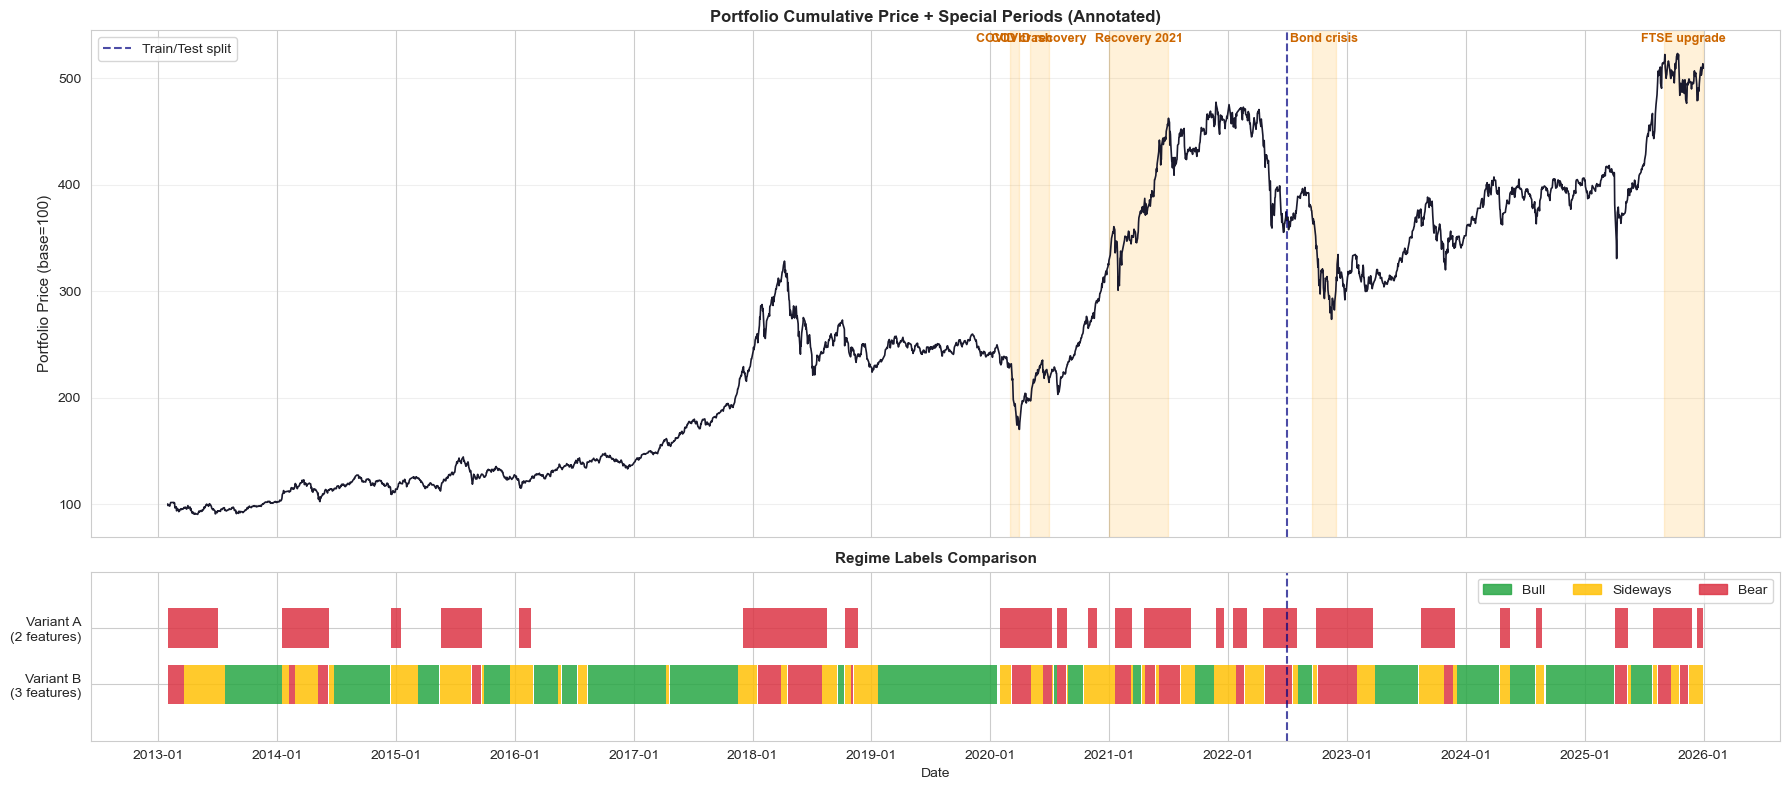

In [7]:
def add_regime_band(ax, regime_series, y_pos, height=0.4, alpha=0.7):
    """Vẽ regime label dưới dạng colored bands."""
    dates = regime_series.index
    labels = regime_series.values
    i = 0
    while i < len(dates):
        label = labels[i]
        j = i + 1
        while j < len(dates) and labels[j] == label:
            j += 1
        ax.fill_between([dates[i], dates[j-1]], y_pos-height/2, y_pos+height/2,
                        color=REGIME_COLORS.get(label, '#cccccc'), alpha=alpha,
                        linewidth=0)
        i = j

# Portfolio cumulative price (normalized)
port_aligned = port.loc[common_idx]
cum_price = (1 + port_aligned['port_ret'].fillna(0)).cumprod() * 100

fig, axes = plt.subplots(2, 1, figsize=(18, 8), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1]})

# Top panel: portfolio price + special period markers
ax1 = axes[0]
ax1.plot(cum_price.index, cum_price.values, color='#1a1a2e', linewidth=1.2)
for name, (start, end) in SPECIAL_PERIODS.items():
    ax1.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='orange', alpha=0.15)
    mid = pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start))/2
    ax1.text(mid, cum_price.max()*1.02, name, ha='center', fontsize=9,
             color='#cc6600', fontweight='bold', rotation=0)
ax1.axvline(pd.Timestamp(TRAIN_END), color='navy', linestyle='--', linewidth=1.5,
            alpha=0.7, label='Train/Test split')
ax1.set_ylabel('Portfolio Price (base=100)', fontsize=11)
ax1.set_title('Portfolio Cumulative Price + Special Periods (Annotated)',
              fontsize=12, fontweight='bold')
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(axis='y', alpha=0.3)

# Bottom panel: 2 regime bands
ax2 = axes[1]
add_regime_band(ax2, a, y_pos=1.0, height=0.35, alpha=0.85)
add_regime_band(ax2, b, y_pos=0.5, height=0.35, alpha=0.85)
ax2.axvline(pd.Timestamp(TRAIN_END), color='navy', linestyle='--', linewidth=1.5, alpha=0.7)
ax2.set_yticks([0.5, 1.0])
ax2.set_yticklabels(['Variant B\n(3 features)', 'Variant A\n(2 features)'], fontsize=10)
ax2.set_ylim(0, 1.5)
ax2.set_xlabel('Date')
ax2.set_title('Regime Labels Comparison', fontsize=11, fontweight='bold')

patches = [mpatches.Patch(color=REGIME_COLORS[r], label=r, alpha=0.85)
           for r in ['Bull','Sideways','Bear']]
ax2.legend(handles=patches, loc='upper right', ncol=3, fontsize=10)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax2.xaxis.set_major_locator(mdates.YearLocator())

plt.tight_layout()
plt.savefig(f'{ROOT}/notebooks/eda/regime_compare_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Phân tích các giai đoạn đặc biệt

Variant nào label đúng cho từng giai đoạn?

=== Special Periods Analysis ===
        Period              Date range  Cum. Return (%) Variant A label Variant B label
   COVID crash 2020-03-01 → 2020-03-31            -28.1     Bear (100%)      Bear (77%)
COVID recovery 2020-05-01 → 2020-06-30              7.8     Bear (100%)  Sideways (62%)
 Recovery 2021 2021-01-01 → 2021-06-30             34.4      Bear (70%)      Bear (58%)
   Bond crisis 2022-09-15 → 2022-11-30            -16.6      Bear (84%)      Bear (78%)
  FTSE upgrade 2025-09-01 → 2025-12-31             -0.0      Bear (90%)  Sideways (60%)


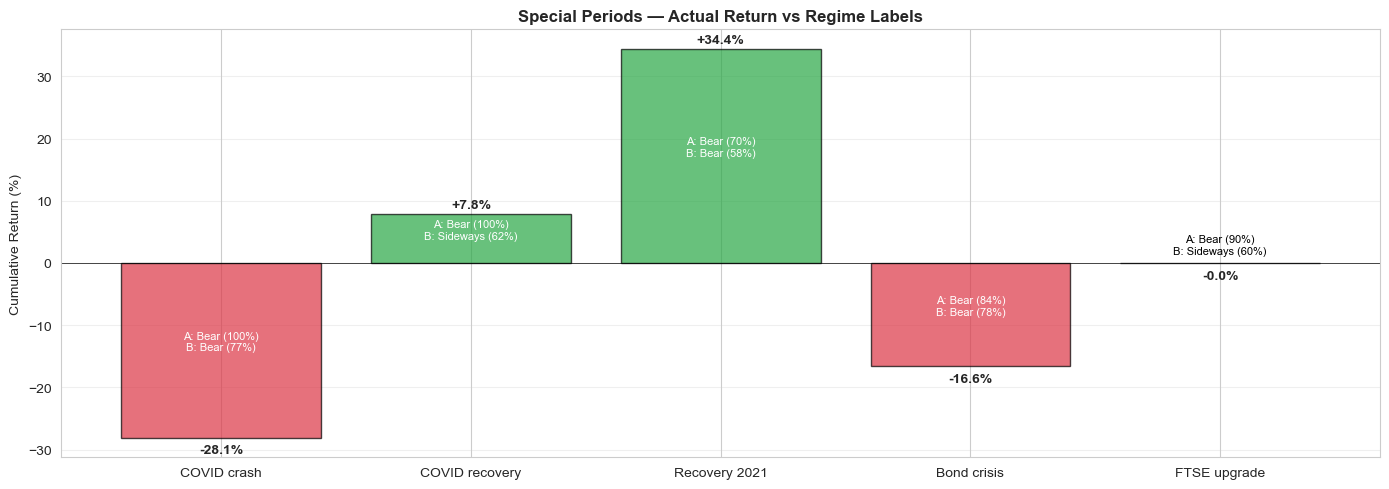

In [ ]:
rows = []
for name, (start, end) in SPECIAL_PERIODS.items():
    sub_a = a.loc[start:end]
    sub_b = b.loc[start:end]
    if len(sub_a) == 0:
        continue
    
    mode_a = sub_a.value_counts().index[0]
    pct_a = sub_a.value_counts().iloc[0] / len(sub_a) * 100
    
    mode_b = sub_b.value_counts().index[0]
    pct_b = sub_b.value_counts().iloc[0] / len(sub_b) * 100
    
    # Actual return trong period
    period_ret = port.loc[start:end, 'port_ret'].sum() * 100  # cumulative return %
    
    rows.append({
        'Period': name,
        'Date range': f'{start} → {end}',
        'Cum. Return (%)': round(period_ret, 1),
        'Variant A label': f'{mode_a} ({pct_a:.0f}%)',
        'Variant B label': f'{mode_b} ({pct_b:.0f}%)',
    })

comparison_df = pd.DataFrame(rows)
print('=== Special Periods Analysis ===')
print(comparison_df.to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(rows))
returns = [r['Cum. Return (%)'] for r in rows]
colors = ['#28a745' if r > 0 else '#dc3545' for r in returns]
bars = ax.bar(x, returns, color=colors, alpha=0.7, edgecolor='black')

for i, (bar, ret) in enumerate(zip(bars, returns)):
    label_a = rows[i]['Variant A label']
    label_b = rows[i]['Variant B label']
    ax.text(bar.get_x()+bar.get_width()/2, ret + (1 if ret>0 else -2.5),
            f'{ret:+.1f}%', ha='center', fontsize=10, fontweight='bold')
    ax.text(bar.get_x()+bar.get_width()/2, ret * 0.5 if abs(ret) > 5 else 1.5,
            f'A: {label_a}\nB: {label_b}', ha='center', fontsize=8,
            color='white' if abs(ret) > 5 else 'black')

ax.set_xticks(x)
ax.set_xticklabels([r['Period'] for r in rows], fontsize=10)
ax.set_ylabel('Cumulative Return (%)')
ax.set_title('Special Periods — Actual Return vs Regime Labels',
             fontsize=12, fontweight='bold')
ax.axhline(0, color='black', linewidth=0.5)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ROOT}/notebooks/eda/regime_compare_special_periods.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Conclusion + Save table cho paper

In [ ]:
# Combined table
combined = pd.concat([summary_a, summary_b], ignore_index=True)
combined = combined[['variant','regime_label','n_days','pct',
                     'ret_annual_pct','vol_annual_pct','sharpe_daily']]
combined.to_csv(OUT_PATH, index=False)
print(f'Saved: {OUT_PATH}\n')

print('=' * 70)
print('CONCLUSION (KEY EVIDENCE FOR PAPER)')
print('=' * 70)

bear_a = summary_a[summary_a['regime_label']=='Bear'].iloc[0]
bear_b = summary_b[summary_b['regime_label']=='Bear'].iloc[0]

print(f'\n[1] Bear annualized return:')
print(f'    Variant A (2-feat): {bear_a["ret_annual_pct"]:+.2f}%')
print(f'    Variant B (3-feat): {bear_b["ret_annual_pct"]:+.2f}%')
print(f'    Improvement: {bear_a["ret_annual_pct"] - bear_b["ret_annual_pct"]:+.2f} pp')

print(f'\n[2] Bear distribution:')
print(f'    Variant A: {bear_a["n_days"]:,} days ({bear_a["pct"]:.1f}%)')
print(f'    Variant B: {bear_b["n_days"]:,} days ({bear_b["pct"]:.1f}%)')

print(f'\n[3] Bear volatility:')
print(f'    Variant A: {bear_a["vol_annual_pct"]:.2f}%')
print(f'    Variant B: {bear_b["vol_annual_pct"]:.2f}%')

print(f'\n[4] Agreement A vs B: {agree:.1f}%')

if bear_b['ret_annual_pct'] < bear_a['ret_annual_pct']:
    print(f'\n>> CONFIRMED: Variant B (3-feature) tách Bear sạch hơn')
    if bear_b['ret_annual_pct'] < 0:
        print(f'   Variant B Bear có annualized return ÂM → true Bear market')
    else:
        print(f'   Variant B Bear vẫn dương nhưng thấp hơn A đáng kể')
else:
    print(f'\n>> UNEXPECTED: 3-feature không cải thiện Bear classification')

Saved: d:\fm-forecasting/data/processed/v2/regime_comparison.csv

CONCLUSION (KEY EVIDENCE FOR PAPER)

[1] Bear annualized return:
    Variant A (2-feat): +2.87%
    Variant B (3-feat): -15.56%
    Improvement: +18.43 pp

[2] Bear distribution:
    Variant A: 1,292 days (40.1%)
    Variant B: 636 days (19.7%)

[3] Bear volatility:
    Variant A: 27.56%
    Variant B: 33.27%

[4] Agreement A vs B: 49.4%

>> CONFIRMED: Variant B (3-feature) tách Bear sạch hơn
   Variant B Bear có annualized return ÂM → true Bear market


## 8. Sanity check — Regime trên giá thực của 1 mã

Vẽ giá thực tế của 1 cổ phiếu (mặc định VCB) với 2 dải regime A/B để **kiểm tra trực quan**:
- Có chỗ nào regime nhìn 'sai' so với hướng giá?
- Variant nào hợp lý hơn?
- Đổi `TICKER` ở đầu cell để xem mã khác (ACB, FPT, HPG, VIC, MSN, GAS...)